# 02 — Preprocessing

Pipeline:
1. Import ClinTox & Tox21 depuis `data/raw/`
2. Nettoyer les SMILES invalides
3. Supprimer les doublons
4. Gérer les valeurs manquantes
5. Combiner ClinTox + Tox21 → `is_toxic`
6. Aperçu du déséquilibre des classes
7. Sauvegarde → `interim/combined_labeled.csv`

> Le split (train/val/test) et tout le feature engineering (Morgan FP, RDKit,
> imputation, scaling) sont réalisés dans **03_feature_engineering.ipynb**.

In [18]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from rdkit import Chem
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

RAW_DIR       = Path('../data/raw')
INTERIM_DIR   = Path('../data/interim')
PROCESSED_DIR = Path('../data/processed')

INTERIM_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Import des datasets

In [19]:
clintox = pd.read_csv(RAW_DIR / 'clintox.csv')
tox21   = pd.read_csv(RAW_DIR / 'tox21.csv')

print(f'ClinTox  : {clintox.shape}')
print(f'Tox21    : {tox21.shape}')
clintox.head(3)

ClinTox  : (1484, 3)
Tox21    : (7831, 14)


,smiles,FDA_APPROVED,CT_TOX
0,*C(=O)[C@H](CCCCNC(=O)OCCOC)NC(=O)OCCOC,1,0
1,[C@@H]1([C@@H]([C@@H]([C@H]([C@@H]([C@@H]1Cl)C...,1,0
2,[C@H]([C@@H]([C@@H](C(=O)[O-])O)O)([C@H](C(=O)...,1,0


In [20]:
tox21.head(3)

,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...


## 2. Nettoyage des SMILES invalides

In [21]:
def is_valid_smiles(smi):
    """Return True if RDKit can parse the SMILES."""
    if not isinstance(smi, str) or smi.strip() == '':
        return False
    return Chem.MolFromSmiles(smi) is not None

clintox['valid'] = clintox['smiles'].apply(is_valid_smiles)
tox21['valid']   = tox21['smiles'].apply(is_valid_smiles)

print(f'ClinTox  — invalides : {(~clintox["valid"]).sum()} / {len(clintox)}')
print(f'Tox21    — invalides : {(~tox21["valid"]).sum()} / {len(tox21)}')

clintox = clintox[clintox['valid']].drop(columns='valid').reset_index(drop=True)
tox21   = tox21[tox21['valid']].drop(columns='valid').reset_index(drop=True)

print(f'\nAprès nettoyage — ClinTox : {clintox.shape} | Tox21 : {tox21.shape}')

ClinTox  — invalides : 4 / 1484
Tox21    — invalides : 8 / 7831

Après nettoyage — ClinTox : (1480, 3) | Tox21 : (7823, 14)


## 3. Suppression des doublons

In [22]:
def canonical(smi):
    mol = Chem.MolFromSmiles(smi)
    return Chem.MolToSmiles(mol, canonical=True) if mol else None

clintox['smiles_can'] = clintox['smiles'].apply(canonical)
tox21['smiles_can']   = tox21['smiles'].apply(canonical)

before_ct  = len(clintox)
before_t21 = len(tox21)

clintox = clintox.drop_duplicates(subset='smiles_can').reset_index(drop=True)
tox21   = tox21.drop_duplicates(subset='smiles_can').reset_index(drop=True)

print(f'ClinTox  — doublons supprimés : {before_ct  - len(clintox)}')
print(f'Tox21    — doublons supprimés : {before_t21 - len(tox21)}')

ClinTox  — doublons supprimés : 19
Tox21    — doublons supprimés : 0


## 4. Gestion des valeurs manquantes

In [23]:
print('=== ClinTox — valeurs manquantes ===')
print(clintox.isnull().sum())

print('\n=== Tox21 — valeurs manquantes (top colonnes) ===')
print(tox21.isnull().sum().sort_values(ascending=False).head(15))

=== ClinTox — valeurs manquantes ===
smiles          0
FDA_APPROVED    0
CT_TOX          0
smiles_can      0
dtype: int64

=== Tox21 — valeurs manquantes (top colonnes) ===
SR-MMP           2019
NR-Aromatase     2008
SR-ARE           1998
NR-ER            1637
NR-PPAR-gamma    1380
SR-HSE           1363
NR-AhR           1281
NR-AR-LBD        1072
SR-p53           1056
NR-ER-LBD         875
SR-ATAD5          758
NR-AR             565
mol_id              0
smiles              0
smiles_can          0
dtype: int64


In [24]:
# ClinTox : supprimer les lignes où CT_TOX est manquant
clintox = clintox.dropna(subset=['CT_TOX']).reset_index(drop=True)

# Tox21 : colonnes cibles — on considère NaN comme non-toxique (0)
# (pratique courante dans les benchmarks MoleculeNet)
tox21_target_cols = [
    'NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase',
    'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma',
    'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53'
]
tox21[tox21_target_cols] = tox21[tox21_target_cols].fillna(0)

print(f'ClinTox après nettoyage NaN : {clintox.shape}')
print(f'Tox21  après nettoyage NaN : {tox21.shape}')

ClinTox après nettoyage NaN : (1461, 4)
Tox21  après nettoyage NaN : (7823, 15)


## 5. Construction du label `is_toxic` & combinaison

In [25]:
# ClinTox : CT_TOX == 1  →  is_toxic = 1
df_ct = clintox[['smiles_can']].copy()
df_ct['is_toxic'] = clintox['CT_TOX'].astype(int)
df_ct['source']   = 'clintox'

# Tox21 : au moins UNE cible positive  →  is_toxic = 1
df_t21 = tox21[['smiles_can']].copy()
df_t21['is_toxic'] = (tox21[tox21_target_cols].max(axis=1) == 1).astype(int)
df_t21['source']   = 'tox21'

df = pd.concat([df_ct, df_t21], ignore_index=True)
df = df.rename(columns={'smiles_can': 'smiles'})

# Supprimer les doublons inter-datasets (garder is_toxic=1 en priorité)
df = (
    df.sort_values('is_toxic', ascending=False)
      .drop_duplicates(subset='smiles')
      .reset_index(drop=True)
)

print(f'Dataset combiné : {df.shape}')
print(df['is_toxic'].value_counts().rename({0: 'Non-toxique', 1: 'Toxique'}))

Dataset combiné : (8799, 3)
is_toxic
Non-toxique    5863
Toxique        2936
Name: count, dtype: int64


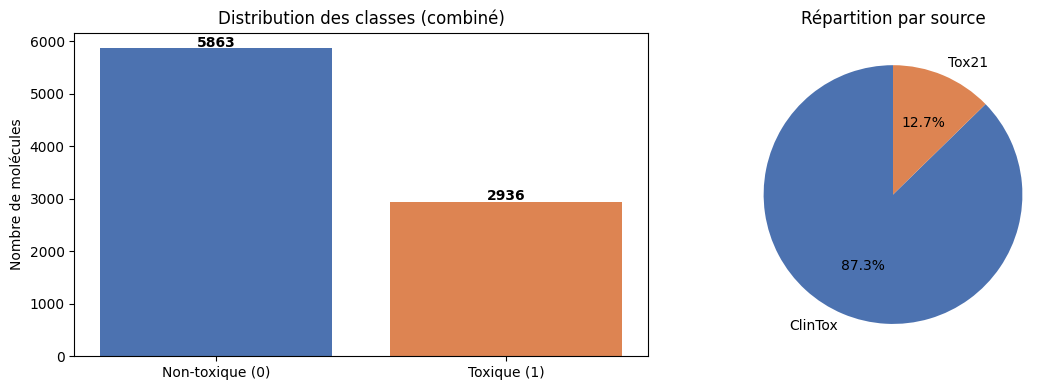

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = ['Non-toxique (0)', 'Toxique (1)']
counts = df['is_toxic'].value_counts().sort_index()

axes[0].bar(labels, counts.values, color=['#4C72B0', '#DD8452'])
axes[0].set_title('Distribution des classes (combiné)')
axes[0].set_ylabel('Nombre de molécules')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, str(v), ha='center', fontweight='bold')

df['source'].value_counts().plot.pie(
    ax=axes[1], autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'],
    startangle=90, labels=['ClinTox', 'Tox21']
)
axes[1].set_title('Répartition par source')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('../reports/figures/class_distribution_combined.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Déséquilibre des classes

In [27]:
y = df['is_toxic'].values
neg, pos = np.bincount(y)
ratio = neg / pos

print(f'Classe 0 (non-toxique) : {neg}')
print(f'Classe 1 (toxique)     : {pos}')
print(f'Ratio imbalance        : {ratio:.2f}x')
print(f'\nStratégie retenue : class_weight="balanced" dans les modèles.')
print(f'Le split et le feature engineering sont réalisés dans le notebook 03.')

Classe 0 (non-toxique) : 5863
Classe 1 (toxique)     : 2936
Ratio imbalance        : 2.00x

Stratégie retenue : class_weight="balanced" dans les modèles.
Le split et le feature engineering sont réalisés dans le notebook 03.


## 7. Sauvegarde

In [28]:
df.to_csv(INTERIM_DIR / 'combined_labeled.csv', index=False)
print('Sauvegardé : interim/combined_labeled.csv')
print(f'→ {len(df)} molécules  |  {(df["is_toxic"]==1).sum()} toxiques ({df["is_toxic"].mean():.1%})')

Sauvegardé : interim/combined_labeled.csv
→ 8799 molécules  |  2936 toxiques (33.4%)


In [29]:
print('=== Résumé final ===')
print(f'Dataset combiné  : {len(df)} molécules')
print(f'  Non-toxiques   : {(df["is_toxic"]==0).sum()}  ({(df["is_toxic"]==0).mean():.1%})')
print(f'  Toxiques       : {(df["is_toxic"]==1).sum()}  ({(df["is_toxic"]==1).mean():.1%})')
print(f'\nOutput          : interim/combined_labeled.csv')
print(f'Étape suivante  : 03_feature_engineering.ipynb  (split + Morgan FP + RDKit + scaling)')

=== Résumé final ===
Dataset combiné  : 8799 molécules
  Non-toxiques   : 5863  (66.6%)
  Toxiques       : 2936  (33.4%)

Output          : interim/combined_labeled.csv
Étape suivante  : 03_feature_engineering.ipynb  (split + Morgan FP + RDKit + scaling)
